In [ ]:
# Load libraries for analysis, reporting, and visual exploration.
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates


In [2]:
# Load cleaned tables and prepare product attributes for the analysis join.
DATA_DIR = Path("../data/cleaned")
REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

sales = pd.read_csv(DATA_DIR / "Sales.csv")
products = pd.read_csv(DATA_DIR / "Products.csv")
customers = pd.read_csv(DATA_DIR / "Customers.csv")
stores = pd.read_csv(DATA_DIR / "Stores.csv")

sales["Order Date"] = pd.to_datetime(
    sales["Order Date"], errors="coerce"
)

products["Unit Price USD"] = pd.to_numeric(
    products["Unit Price USD"], errors="coerce"
)
products["Unit Cost USD"] = pd.to_numeric(
    products["Unit Cost USD"], errors="coerce"
)

# Add product information to each sales line
df = sales.merge(
    products[
        [
            "ProductKey", "Product Name", "Brand",
            "Category", "Subcategory",
            "Unit Price USD", "Unit Cost USD"
        ]
    ],
    on="ProductKey",
    how="left",
    validate="many_to_one"
)

# Business metrics
df["Revenue USD"] = df["Quantity"] * df["Unit Price USD"]
df["COGS USD"] = df["Quantity"] * df["Unit Cost USD"]
df["Gross Profit USD"] = df["Revenue USD"] - df["COGS USD"]

df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.to_period("M").astype(str)

print("Sales lines:", len(df))
print("Unique orders:", df["Order Number"].nunique())
print("Unmatched product prices:", df["Unit Price USD"].isna().sum())

Sales lines: 62884
Unique orders: 26326
Unmatched product prices: 0


In [2]:
# Calculate and export the project-level KPI summary.
total_revenue = df["Revenue USD"].sum()
total_cogs = df["COGS USD"].sum()
total_profit = df["Gross Profit USD"].sum()
total_orders = df["Order Number"].nunique()
total_units = df["Quantity"].sum()

summary = pd.DataFrame({
    "Metric": [
        "Revenue USD",
        "COGS USD",
        "Gross Profit USD",
        "Gross Margin %",
        "Distinct Orders",
        "Units Sold",
        "Average Order Value USD"
    ],
    "Value": [
        total_revenue,
        total_cogs,
        total_profit,
        total_profit / total_revenue if total_revenue else np.nan,
        total_orders,
        total_units,
        total_revenue / total_orders if total_orders else np.nan
    ]
})

display(summary)
summary.to_csv(REPORT_DIR / "eda_kpi_summary.csv", index=False)

,Metric,Value
0,Revenue USD,5.575548e+07
1,COGS USD,2.309279e+07
2,Gross Profit USD,3.266269e+07
3,Gross Margin %,5.858202e-01
4,Distinct Orders,2.632600e+04
5,Units Sold,1.977570e+05
6,Average Order Value USD,2.117886e+03


In [ ]:
# Aggregate revenue, orders, and units by calendar month.


monthly = (
    df.dropna(subset=["Order Date"])
      .groupby(df["Order Date"].dt.to_period("M"))
      .agg(
          Revenue=("Revenue USD", "sum"),
          Orders=("Order Number", "nunique"),
          Units=("Quantity", "sum")
      )
      .reset_index(names="Month")
)

monthly["Month"] = monthly["Month"].dt.to_timestamp()
print("Monthly revenue trend:")
display(monthly)


,Month,Revenue,Orders,Units
0,2016-01-01,649918.78,292,2116
1,2016-02-01,891098.30,334,2676
2,2016-03-01,338407.36,109,895
3,2016-04-01,110591.63,41,326
4,2016-05-01,595986.18,220,1646
...,...,...,...,...
57,2020-10-01,245647.59,159,1042
58,2020-11-01,256701.02,149,1044
59,2020-12-01,651526.44,318,2411
60,2021-01-01,513021.58,256,1848


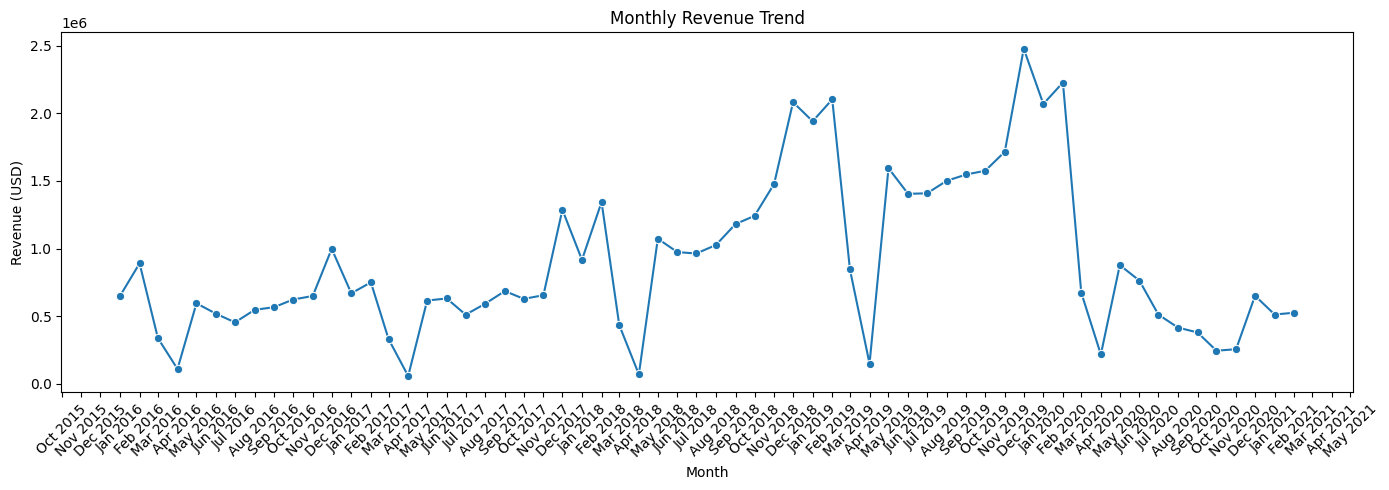

In [23]:
# Visualize the monthly revenue trend with readable date labels.
# plot monthly revenue trend
plt.figure(figsize=(14, 5))

sns.lineplot(data=monthly, x="Month", y="Revenue", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (USD)")

# Display a tick for every month
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=1))

# Format month labels
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
# Aggregate revenue and orders by year for annual comparison.
yearly = (
    df.dropna(subset=["Order Date"])
      .groupby(df["Order Date"].dt.year)
      .agg(
          Revenue=("Revenue USD", "sum"),
          Orders=("Order Number", "nunique")
      )
      .rename_axis("Year")
      .reset_index()
)

display(yearly)

,Year,Revenue,Orders
0,2016,6946793.56,2865
1,2017,7421422.27,3280
2,2018,12788960.66,5965
3,2019,18264382.48,9083
4,2020,9294632.14,4635
5,2021,1039288.48,498


In [12]:
# Summarize category revenue, profitability, volume, margin, and revenue share.
category_summary = (
    df.groupby("Category")
      .agg(
          Revenue=("Revenue USD", "sum"),
          Gross_Profit=("Gross Profit USD", "sum"),
          Units=("Quantity", "sum"),
          Orders=("Order Number", "nunique")
      )
      .reset_index()
)

category_summary["Gross_Margin"] = (
    category_summary["Gross_Profit"]
    / category_summary["Revenue"]
)

category_summary["Revenue_Share"] = (
    category_summary["Revenue"] / total_revenue
)

category_summary = category_summary.sort_values(
    "Revenue", ascending=False
)

display(category_summary.round(3))

,Category,Revenue,Gross_Profit,Units,Orders,Gross_Margin,Revenue_Share
3,Computers,19301595.46,11277447.90,44151,10990,0.584,0.346
5,Home Appliances,10795478.59,6296338.85,18401,5195,0.583,0.194
1,Cameras and camcorders,6520168.02,3919800.99,17609,4995,0.601,0.117
2,Cell phones,6183791.22,3498626.54,31477,8442,0.566,0.111
7,TV and Video,5928982.69,3536694.39,11236,3325,0.597,0.106
0,Audio,3169627.74,1827851.77,23490,6625,0.577,0.057
6,"Music, Movies and Audio Books",3131006.44,1909259.17,28802,7784,0.610,0.056
4,Games and Toys,724829.43,396668.77,22591,6128,0.547,0.013


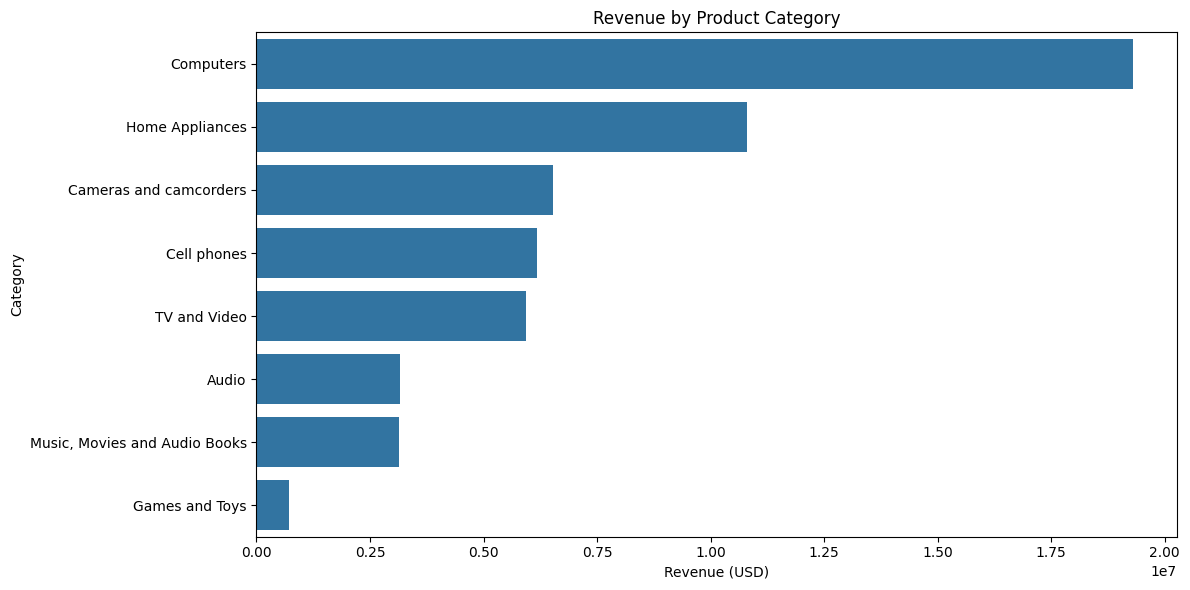

In [13]:
# Plot revenue by product category to compare category scale.
plt.figure(figsize=(12, 6))
sns.barplot(
    data=category_summary,
    x="Revenue",
    y="Category"
)
plt.title("Revenue by Product Category")
plt.xlabel("Revenue (USD)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

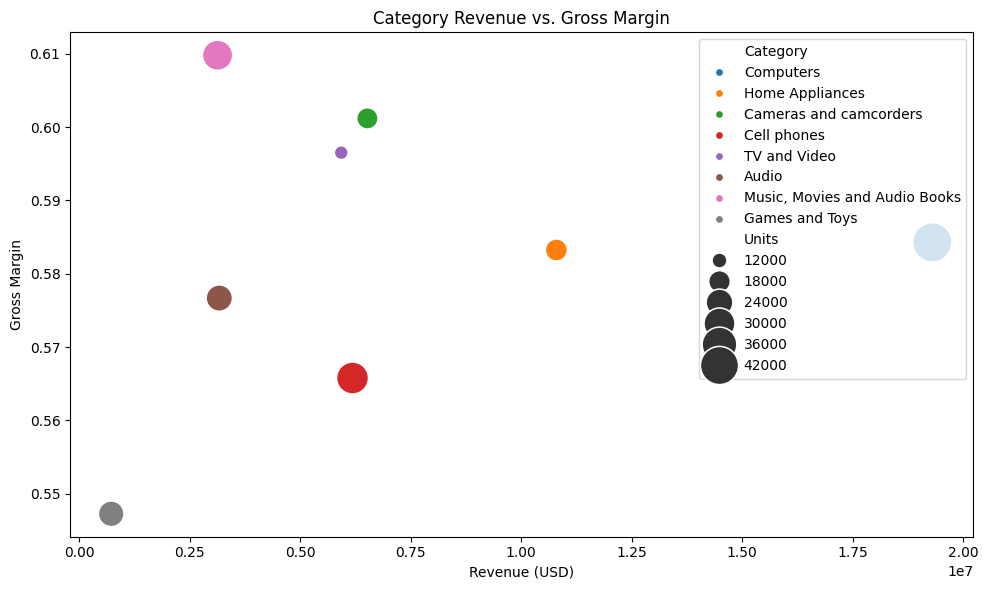

In [14]:
# Compare category revenue with gross margin and unit volume.
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=category_summary,
    x="Revenue",
    y="Gross_Margin",
    size="Units",
    hue="Category",
    sizes=(100, 800)
)
plt.title("Category Revenue vs. Gross Margin")
plt.xlabel("Revenue (USD)")
plt.ylabel("Gross Margin")
plt.tight_layout()
plt.show()

In [15]:
# Summarize brand-level revenue, profit, and units sold.
brand_summary = (
    df.groupby("Brand")
      .agg(
          Revenue=("Revenue USD", "sum"),
          Gross_Profit=("Gross Profit USD", "sum"),
          Units=("Quantity", "sum")
      )
      .reset_index()
      .sort_values("Revenue", ascending=False)
)

display(brand_summary.head(10))

,Brand,Revenue,Gross_Profit,Units
1,Adventure Works,11849909.32,6937318.88,20099
2,Contoso,10792325.32,6321209.14,49827
10,Wide World Importers,9172800.41,5367028.30,27413
3,Fabrikam,6807893.52,4061475.11,11384
9,The Phone Company,5386820.00,3057762.90,18764
6,Proseware,3212628.02,1935287.10,9427
4,Litware,2659498.78,1553765.19,5309
7,Southridge Video,2578595.93,1522876.84,24814
0,A. Datum,1486207.80,883502.31,5655
5,Northwind Traders,1126069.54,649413.31,7610


In [16]:
# Summarize product performance and identify the highest-revenue products.
product_summary = (
    df.groupby(["ProductKey", "Product Name", "Category", "Brand"])
      .agg(
          Revenue=("Revenue USD", "sum"),
          Gross_Profit=("Gross Profit USD", "sum"),
          Units=("Quantity", "sum"),
          Orders=("Order Number", "nunique")
      )
      .reset_index()
)

product_summary["Gross_Margin"] = (
    product_summary["Gross_Profit"] / product_summary["Revenue"]
)

top_products = product_summary.sort_values(
    "Revenue", ascending=False
).head(10)

display(top_products)

,ProductKey,Product Name,Category,Brand,Revenue,Gross_Profit,Units,Orders,Gross_Margin
442,444,WWI Desktop PC2.33 X2330 Black,Computers,Wide World Importers,505450.00,337986.00,550,154,0.668683
414,416,Adventure Works Desktop PC2.33 XD233 Silver,Computers,Adventure Works,466089.00,311663.95,481,146,0.668679
426,428,Adventure Works Desktop PC2.33 XD233 Brown,Computers,Adventure Works,464151.00,310368.05,479,144,0.668679
420,422,Adventure Works Desktop PC2.33 XD233 Black,Computers,Adventure Works,447678.00,299352.90,462,151,0.668679
431,433,Adventure Works Desktop PC2.33 XD233 White,Computers,Adventure Works,437019.00,292225.45,451,141,0.668679
453,455,WWI Desktop PC2.33 X2330 White,Computers,Wide World Importers,424578.00,283908.24,462,131,0.668683
448,450,WWI Desktop PC2.33 X2330 Brown,Computers,Wide World Importers,422740.00,282679.20,460,151,0.668683
146,147,"Adventure Works 52"" LCD HDTV X590 White",TV and Video,Adventure Works,394398.64,263727.12,136,40,0.668682
145,146,"Adventure Works 52"" LCD HDTV X590 Black",TV and Video,Adventure Works,374098.71,250152.93,129,44,0.668682
436,438,WWI Desktop PC2.33 X2330 Silver,Computers,Wide World Importers,360248.00,240891.84,392,141,0.668683


In [17]:
# Join store attributes and summarize performance by store or sales channel.
store_df = df.merge(
    stores[["StoreKey", "Country", "State", "Square Meters"]],
    on="StoreKey",
    how="left",
    validate="many_to_one"
)

store_summary = (
    store_df.groupby(["StoreKey", "Country", "State"], dropna=False)
      .agg(
          Revenue=("Revenue USD", "sum"),
          Gross_Profit=("Gross Profit USD", "sum"),
          Orders=("Order Number", "nunique"),
          Units=("Quantity", "sum")
      )
      .reset_index()
)

store_summary["Gross_Margin"] = (
    store_summary["Gross_Profit"] / store_summary["Revenue"]
)

display(
    store_summary.sort_values("Revenue", ascending=False).head(15)
)

,StoreKey,Country,State,Revenue,Gross_Profit,Orders,Units,Gross_Margin
0,0,Online,Online,11404324.63,6672692.64,5580,41311,0.585102
48,55,United States,Nevada,1417885.41,830551.75,622,4826,0.585768
44,50,United States,Kansas,1394738.06,819659.12,605,4773,0.587680
47,54,United States,Nebraska,1384396.24,810300.06,629,4686,0.585309
7,9,Canada,Northwest Territories,1336150.06,774757.55,658,4894,0.579843
50,57,United States,New Mexico,1325611.89,784095.76,605,4407,0.591497
40,45,United States,Connecticut,1318787.92,761271.82,617,4672,0.577251
52,61,United States,South Carolina,1305684.43,764997.20,624,4771,0.585897
51,59,United States,Oregon,1302272.44,754702.32,619,4674,0.579527
55,64,United States,Washington DC,1259350.98,745283.99,566,4289,0.591800


In [18]:
# Join customer attributes and summarize revenue by customer.
customer_df = df.merge(
    customers[
        ["CustomerKey", "Country", "Continent", "Gender", "Birthday"]
    ],
    on="CustomerKey",
    how="left",
    validate="many_to_one"
)

customer_summary = (
    customer_df.groupby("CustomerKey")
      .agg(
          Revenue=("Revenue USD", "sum"),
          Gross_Profit=("Gross Profit USD", "sum"),
          Orders=("Order Number", "nunique"),
          Units=("Quantity", "sum")
      )
      .reset_index()
)

customer_summary = customer_summary.sort_values(
    "Revenue", ascending=False
)

display(customer_summary.head(10))

,CustomerKey,Revenue,Gross_Profit,Orders,Units
9371,1702221,61871.70,39606.02,9,75
10515,1884663,43517.80,28819.96,3,30
11072,1969704,42788.04,26008.23,7,60
2743,535496,41521.53,26957.37,3,35
2840,551036,40556.54,26716.09,4,36
3664,723572,40225.01,23440.78,14,124
1175,262871,38813.88,23986.19,3,32
10795,1928466,38191.06,24054.60,4,40
8116,1503831,37319.88,22881.47,3,29
7275,1373561,36817.28,22954.48,5,62


In [19]:
# Calculate individual customer revenue share and concentration metrics.
customer_summary["Revenue_Share"] = (
    customer_summary["Revenue"] / total_revenue
)

customer_summary["Cumulative_Revenue_Share"] = (
    customer_summary["Revenue_Share"].cumsum()
)

top_10_customer_share = (
    customer_summary.head(10)["Revenue"].sum() / total_revenue
)

top_100_customer_share = (
    customer_summary.head(100)["Revenue"].sum() / total_revenue
)

print(f"Top 10 customers' revenue share: {top_10_customer_share:.2%}")
print(f"Top 100 customers' revenue share: {top_100_customer_share:.2%}")

Top 10 customers' revenue share: 0.76%
Top 100 customers' revenue share: 5.53%


In [20]:
# Summarize revenue, profit, customers, and orders by customer country.
customer_country_summary = (
    customer_df.groupby("Country")
      .agg(
          Revenue=("Revenue USD", "sum"),
          Gross_Profit=("Gross Profit USD", "sum"),
          Customers=("CustomerKey", "nunique"),
          Orders=("Order Number", "nunique")
      )
      .reset_index()
      .sort_values("Revenue", ascending=False)
)

display(customer_country_summary)

,Country,Revenue,Gross_Profit,Customers,Orders
7,United States,29871631.17,17490924.05,5706,14221
6,United Kingdom,7084088.12,4133800.81,1570,3421
3,Germany,5414149.80,3185916.46,1150,2440
1,Canada,4724334.63,2755738.22,1179,2281
0,Australia,2708137.61,1597300.18,780,1182
4,Italy,2475645.77,1450851.09,530,1101
5,Netherlands,1962154.27,1154644.08,534,976
2,France,1515338.22,893513.49,438,704


In [21]:
# Export all analysis tables for Tableau use and reproducible reporting.
summary.to_csv(
    REPORT_DIR / "eda_kpi_summary.csv", index=False
)

monthly.to_csv(
    REPORT_DIR / "monthly_sales_trend.csv", index=False
)

category_summary.to_csv(
    REPORT_DIR / "category_performance.csv", index=False
)

brand_summary.to_csv(
    REPORT_DIR / "brand_performance.csv", index=False
)

product_summary.to_csv(
    REPORT_DIR / "product_performance.csv", index=False
)

store_summary.to_csv(
    REPORT_DIR / "store_performance.csv", index=False
)

customer_summary.to_csv(
    REPORT_DIR / "customer_performance.csv", index=False
)

customer_country_summary.to_csv(
    REPORT_DIR / "customer_country_performance.csv", index=False
)

print("EDA summary tables exported.")

EDA summary tables exported.
